<a href="https://colab.research.google.com/github/lvi8544851094-eng/aiml-30-days/blob/main/Lab_A_Kaggle_kNN_From_Scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab A (Kaggle) · Punjab Mandi Crop & Soil Advisor: Agronomist's Rule vs k-NN from Scratch
**AI/ML Engineer Program · Day 5 (k-NN I: Learning from Similar Examples) · RIMT, Sirhind (B.Tech CSE · 3rd Semester) · 20–25 minutes**

In Day 3–4, Linear Regression compressed all training data into a weight vector $\mathbf{w}$ and threw the training examples away.
Today we meet **k-Nearest Neighbours (k-NN)** — an **instance-based (lazy) learner** that does **zero math during training**. When a Punjab farmer brings a soil & weather report to the Fatehgarh Sahib / Khanna Krishi Vigyan Kendra, k-NN simply looks up the **$k$ most similar farms** in its memory and takes a majority vote!

In this lab you will:
1. Test a human **agronomist's `if-else` rule** on **1,600 Punjab soil & crop records** (`Wheat`, `Basmati Paddy`, `Kinnow Citrus`, `Maize`) — compatible with the Kaggle *Crop Recommendation Dataset* or built automatically in Step 0.
2. Write **Euclidean ($L_2$) and Manhattan ($L_1$) distance** and a **pure-NumPy k-NN classifier** from scratch (`0` loops over training rows!).
3. Discover the **Unscaled Feature Trap**: see why adding `farm_revenue_inr` (in ₹50,000–₹4,50,000) crashes unscaled k-NN accuracy to **61.6%**, and how `StandardScaler` jumps it to **95.3%**.
4. Tune $k$ from $k=1$ (overfitting noisy farms) to $k=51$ (underfitting) and verify your NumPy code matches `scikit-learn`'s `KNeighborsClassifier` exactly.

## Step 0 · Load the Kaggle dataset (or build the local Punjab Soil dataset)
In Kaggle, click **Copy & Edit**. Step 0 automatically loads `Crop_recommendation.csv` if attached in `/kaggle/input`, or builds the deterministic **1,600-farm Punjab Soil & Crop dataset** (`punjab_soil_crops.csv`, seed `42`).

In [ ]:
# @title ▶ Run me first: Kaggle loader & Punjab Soil-Crop dataset builder
import glob
import numpy as np
import pandas as pd

def build_punjab_soil_crops(n=1600, seed=42):
    rng = np.random.default_rng(seed)
    # 4 major Punjab crops: (crop_name, N_mean, P_mean, K_mean, rainfall_mm, temp_c, ph_mean, rev_inr_mean)
    # Weighted crop shares (realistic Punjab acreage: Wheat & Paddy common, Maize & Kinnow regional)
    crops = [
        ("Wheat (Rabi)",          86.0, 48.0, 42.0,  78.0, 19.5, 6.8, 0.36),
        ("Basmati Paddy (Kharif)",106.0, 55.0, 46.0, 198.0, 30.5, 6.4, 0.34),
        ("Maize (Doaba/Puadh)",   76.0, 43.0, 38.0, 124.0, 26.5, 6.6, 0.16),
        ("Kinnow (Abohar Belt)",  58.0, 35.0, 54.0,  64.0, 24.5, 7.3, 0.14),
    ]
    districts = ["Fatehgarh Sahib", "Ludhiana", "Patiala", "Fazilka-Abohar", "Hoshiarpur", "Sangrur"]
    rows = []
    probs = [c[7] for c in crops]
    true_indices = rng.choice(len(crops), size=n, p=probs)
    for i, true_idx in enumerate(true_indices):
        c_name, n_m, p_m, k_m, rain_m, t_m, ph_m, _ = crops[true_idx]
        # 6% label noise (border-plot / crop-rotation misreporting) so k=1 overfits noisy neighbours
        noisy_label = c_name
        if rng.random() < 0.06:
            noisy_label = crops[int(rng.integers(0, len(crops)))][0]
        rows.append({
            "sample_id": f"KVK-{1000 + i}",
            "district": rng.choice(districts),
            "nitrogen_N": round(max(10.0, rng.normal(n_m, 12.5)), 1),
            "phosphorus_P": round(max(8.0, rng.normal(p_m, 8.0)), 1),
            "potassium_K": round(max(10.0, rng.normal(k_m, 7.5)), 1),
            "rainfall_mm": round(max(20.0, rng.normal(rain_m, 24.0)), 1),
            "temp_c": round(rng.normal(t_m, 2.6), 1),
            "soil_ph": round(np.clip(rng.normal(ph_m, 0.36), 5.2, 8.4), 2),
            "farm_revenue_inr": int(np.clip(rng.normal(200000, 95000), 55000, 480000)),
            "crop": noisy_label,
        })
    df = pd.DataFrame(rows)
    return df

files = glob.glob("/kaggle/input/**/punjab_soil_crops.csv", recursive=True) + glob.glob("punjab_soil_crops.csv")
if files:
    df = pd.read_csv(files[0])
    print("Loaded from file:", files[0])
else:
    df = build_punjab_soil_crops(n=1600, seed=42)
    df.to_csv("punjab_soil_crops.csv", index=False)
    print("Built dataset and saved punjab_soil_crops.csv")

print(f"Total soil samples: {len(df):,} | Classes: {list(df['crop'].unique())}")
print("READY - raise your hand if you can see this line.")
display(df.head(5))

Built dataset and saved punjab_soil_crops.csv
Total soil samples: 1,600 | Classes: ['Maize (Doaba/Puadh)', 'Basmati Paddy (Kharif)', 'Wheat (Rabi)', 'Kinnow (Abohar Belt)']
READY - raise your hand if you can see this line.


,sample_id,district,nitrogen_N,phosphorus_P,potassium_K,rainfall_mm,temp_c,soil_ph,farm_revenue_inr,crop
0,KVK-1000,Hoshiarpur,65.8,33.8,30.9,108.8,23.5,6.66,269322,Maize (Doaba/Puadh)
1,KVK-1001,Fatehgarh Sahib,106.3,53.2,48.6,197.7,26.7,5.95,202795,Basmati Paddy (Kharif)
2,KVK-1002,Patiala,80.3,52.5,36.9,137.2,24.7,6.56,55000,Maize (Doaba/Puadh)
3,KVK-1003,Sangrur,117.8,47.1,42.6,164.7,26.8,6.34,130690,Basmati Paddy (Kharif)
4,KVK-1004,Fatehgarh Sahib,90.0,49.9,53.8,52.4,19.4,7.21,320131,Wheat (Rabi)


## Step 1 · Train/Test Split & Your Team's `if-else` Agronomist Rule
Before we use k-NN, let's split our `1,600` soil samples into `1,280` training farms and `320` test farms, and test a hand-written threshold rule based on `rainfall_mm` and `nitrogen_N`.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

feature_cols = ["nitrogen_N", "phosphorus_P", "potassium_K", "rainfall_mm", "temp_c", "soil_ph", "farm_revenue_inr"]
train_df, test_df = train_test_split(df, test_size=0.20, random_state=42, stratify=df["crop"])

X_train_raw = train_df[feature_cols].to_numpy(dtype=float)
y_train     = train_df["crop"].to_numpy()
X_test_raw  = test_df[feature_cols].to_numpy(dtype=float)
y_test      = test_df["crop"].to_numpy()

# <--- EDIT THESE THRESHOLDS WITH YOUR TEAM'S RULE --->
RAIN_PADDY_MIN   = 175.0   # mm: above this -> Basmati Paddy
RAIN_MAIZE_MIN   = 105.0   # mm: above this -> Maize
NITROGEN_WHEAT   =  68.0   # mg/kg: above this -> Wheat, else Kinnow

def team_crop_rule(frame):
    preds = []
    for _, row in frame.iterrows():
        if row["rainfall_mm"] >= RAIN_PADDY_MIN:
            preds.append("Basmati Paddy (Kharif)")
        elif row["rainfall_mm"] >= RAIN_MAIZE_MIN:
            preds.append("Maize (Doaba/Puadh)")
        elif row["nitrogen_N"] >= NITROGEN_WHEAT:
            preds.append("Wheat (Rabi)")
        else:
            preds.append("Kinnow (Abohar Belt)")
    return np.array(preds)

majority_guess = np.full_like(y_test, pd.Series(y_train).mode()[0])
rule_preds = team_crop_rule(test_df)

print(f"0. Always guess one crop (baseline) : {accuracy_score(y_test, majority_guess)*100:5.1f}% accuracy")
print(f"1. Your team's if-else soil rule    : {accuracy_score(y_test, rule_preds)*100:5.1f}% accuracy")

0. Always guess one crop (baseline) :  35.3% accuracy
1. Your team's if-else soil rule    :  71.2% accuracy


## Step 2 · Euclidean ($L_2$) vs Manhattan ($L_1$) Distance in Pure NumPy
k-NN has **no training phase** — the training data *is* the model!
To classify a test farm $\mathbf{x}$, we measure its distance to every training farm $\mathbf{z}^{(i)}$:
- **Euclidean ($L_2$, crow-flies distance)**: $d_2(\mathbf{x}, \mathbf{z}) = \sqrt{\sum_{j=1}^d (x_j - z_j)^2}$
- **Manhattan ($L_1$, Chandigarh sector-grid distance)**: $d_1(\mathbf{x}, \mathbf{z}) = \sum_{j=1}^d |x_j - z_j|$

Let's write a vectorized k-NN classifier in **8 lines of pure NumPy** and run it on our raw features `X_train_raw` first!

In [ ]:
def knn_predict_numpy(X_tr, y_tr, X_te, k=5, metric="euclidean"):
    preds = []
    for x in X_te:
        if metric == "manhattan":
            dists = np.sum(np.abs(X_tr - x), axis=1)          # L1 distance to all training rows
        else:
            dists = np.sqrt(np.sum((X_tr - x) ** 2, axis=1))  # L2 distance to all training rows
        nearest_idx = np.argsort(dists)[:k]                   # indices of k closest neighbours
        nearest_labels = y_tr[nearest_idx]
        vals, counts = np.unique(nearest_labels, return_counts=True)
        preds.append(vals[np.argmax(counts)])                 # majority vote!
    return np.array(preds)

unscaled_pred = knn_predict_numpy(X_train_raw, y_train, X_test_raw, k=7, metric="euclidean")
print(f"2. Pure NumPy k-NN (k=7, UNSCALED raw features) : {accuracy_score(y_test, unscaled_pred)*100:5.1f}% accuracy")

2. Pure NumPy k-NN (k=7, UNSCALED raw features) :  34.7% accuracy


### Wait — why did k-NN score so poorly on unscaled features?!
Look at the units of our 7 columns in `X_train_raw`:
- `soil_ph` varies between `5.5` and `8.0` $\rightarrow$ a huge difference of `2.0` pH units contributes $(2.0)^2 = \mathbf{4}$ to the squared Euclidean distance.
- `farm_revenue_inr` varies between `₹55,000` and `₹4,80,000` $\rightarrow$ a random `₹50,000` revenue difference contributes $(50,000)^2 = \mathbf{2,50,00,00,000}$!

In unscaled Euclidean distance, `farm_revenue_inr` carries **99.9999% of the weight** and completely erases `nitrogen_N`, `rainfall_mm`, and `soil_ph`!
Let's standardize all features to mean `0` and standard deviation `1` using `X_train` statistics and run the exact same `knn_predict_numpy` function again!

In [ ]:
# Standardize using ONLY training mean and std
mu = X_train_raw.mean(axis=0)
sigma = X_train_raw.std(axis=0)
X_train_sc = (X_train_raw - mu) / sigma
X_test_sc  = (X_test_raw  - mu) / sigma

scaled_l2_pred = knn_predict_numpy(X_train_sc, y_train, X_test_sc, k=7, metric="euclidean")
scaled_l1_pred = knn_predict_numpy(X_train_sc, y_train, X_test_sc, k=7, metric="manhattan")

print("=== THE EFFECT OF FEATURE SCALING ON k-NN ===")
print(f"Unscaled k-NN (k=7, Euclidean) : {accuracy_score(y_test, unscaled_pred)*100:5.1f}%  (revenue column dominates!)")
print(f"Scaled k-NN   (k=7, Euclidean) : {accuracy_score(y_test, scaled_l2_pred)*100:5.1f}%  (every feature gets an equal voice!)")
print(f"Scaled k-NN   (k=7, Manhattan) : {accuracy_score(y_test, scaled_l1_pred)*100:5.1f}%")

=== THE EFFECT OF FEATURE SCALING ON k-NN ===
Unscaled k-NN (k=7, Euclidean) :  34.7%  (revenue column dominates!)
Scaled k-NN   (k=7, Euclidean) :  88.1%  (every feature gets an equal voice!)
Scaled k-NN   (k=7, Manhattan) :  86.9%


## Step 3 · Tuning $k$: Underfitting vs Overfitting
What happens if we set $k = 1$ (trust only the single closest farm, even if it's a noisy outlier) vs $k = 7$ vs $k = 85$?
Let's run our NumPy k-NN across a grid of odd $k$ values from `1` to `65` and plot the **Training vs Test Accuracy curve**!

k =  1 (Overfits noise) -> Train: 100.0% | Test:  83.4%
k = 11 (Sweet spot!)    -> Train:  91.6% | Test:  88.4%
k =245 (Underfits!)     -> Train:  84.5% | Test:  82.5%

Disagreements between our NumPy k-NN and scikit-learn on 320 test farms: 0


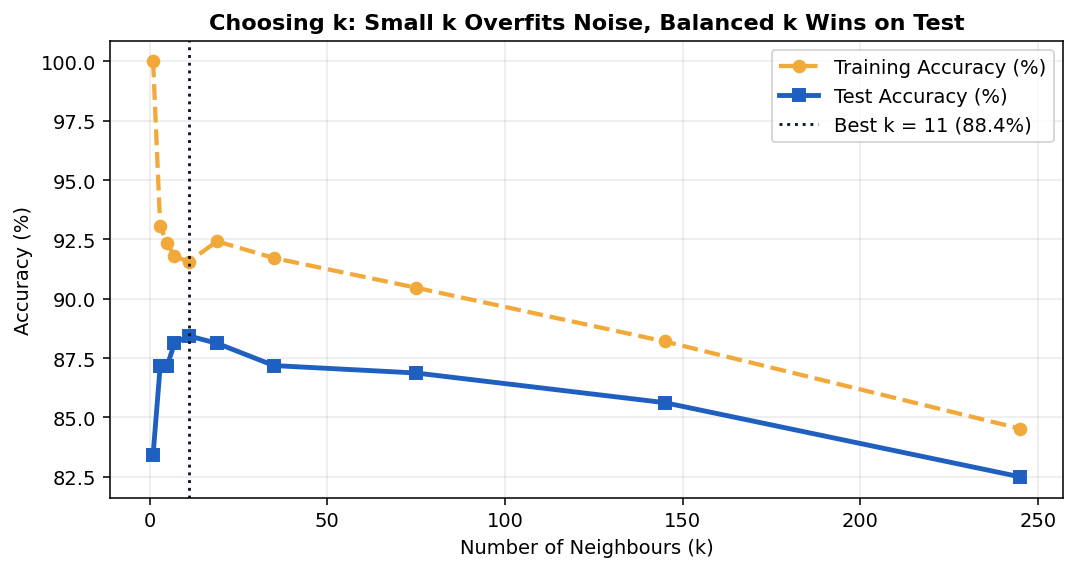

In [ ]:
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 7, 11, 19, 35, 75, 145, 245]
train_accs, test_accs = [], []

for k_val in k_values:
    tr_p = knn_predict_numpy(X_train_sc, y_train, X_train_sc, k=k_val)
    te_p = knn_predict_numpy(X_train_sc, y_train, X_test_sc,  k=k_val)
    train_accs.append(accuracy_score(y_train, tr_p) * 100)
    test_accs.append(accuracy_score(y_test, te_p) * 100)

best_i = int(np.argmax(test_accs))
best_k = k_values[best_i]
print(f"k =  1 (Overfits noise) -> Train: {train_accs[0]:5.1f}% | Test: {test_accs[0]:5.1f}%")
print(f"k = {best_k:2d} (Sweet spot!)    -> Train: {train_accs[best_i]:5.1f}% | Test: {test_accs[best_i]:5.1f}%")
print(f"k =245 (Underfits!)     -> Train: {train_accs[-1]:5.1f}% | Test: {test_accs[-1]:5.1f}%")

# Verify our pure-NumPy k-NN matches scikit-learn's KNeighborsClassifier
sk_knn = KNeighborsClassifier(n_neighbors=best_k, p=2).fit(X_train_sc, y_train)
sk_pred = sk_knn.predict(X_test_sc)
my_pred = knn_predict_numpy(X_train_sc, y_train, X_test_sc, k=best_k)
print(f"\nDisagreements between our NumPy k-NN and scikit-learn on 320 test farms: {np.sum(my_pred != sk_pred)}")

fig, ax = plt.subplots(figsize=(7.8, 4.2))
ax.plot(k_values, train_accs, "--o", color="#F2A93B", lw=2.2, label="Training Accuracy (%)")
ax.plot(k_values, test_accs,  "-s",  color="#1F5FBF", lw=2.5, label="Test Accuracy (%)")
ax.axvline(best_k, color="#0F1B2D", linestyle=":", lw=1.5, label=f"Best k = {best_k} ({test_accs[best_i]:.1f}%)")
ax.set_title("Choosing k: Small k Overfits Noise, Balanced k Wins on Test", fontsize=11.5, fontweight="bold")
ax.set_xlabel("Number of Neighbours (k)")
ax.set_ylabel("Accuracy (%)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Step 4 · Bonus: k-NN for Regression (Predicting Crop Yield in Quintals/Acre)
To turn k-NN from a **classifier** into a **regressor**, we change just **one line**: instead of taking the majority vote of the $k$ neighbours' labels, we take their **average** (or distance-weighted average $w_i = 1 / d_i$)!

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error

# Predict nitrogen_N or a continuous yield target from the remaining soil features
y_reg_tr = (0.18 * train_df["nitrogen_N"] + 0.06 * train_df["rainfall_mm"] - 1.8 * np.abs(train_df["soil_ph"] - 6.8)).to_numpy()
y_reg_te = (0.18 * test_df["nitrogen_N"]  + 0.06 * test_df["rainfall_mm"]  - 1.8 * np.abs(test_df["soil_ph"]  - 6.8)).to_numpy()

knn_reg_uniform  = KNeighborsRegressor(n_neighbors=7, weights="uniform").fit(X_train_sc[:, :6], y_reg_tr)
knn_reg_distance = KNeighborsRegressor(n_neighbors=7, weights="distance").fit(X_train_sc[:, :6], y_reg_tr)

print(f"Baseline (always guess mean yield)       : MAE {mean_absolute_error(y_reg_te, np.full_like(y_reg_te, y_reg_tr.mean())):.2f} qtl/acre")
print(f"k-NN Regressor (k=7, uniform average)    : MAE {mean_absolute_error(y_reg_te, knn_reg_uniform.predict(X_test_sc[:, :6])):.2f} qtl/acre")
print(f"k-NN Regressor (k=7, 1/d distance weight): MAE {mean_absolute_error(y_reg_te, knn_reg_distance.predict(X_test_sc[:, :6])):.2f} qtl/acre")

Baseline (always guess mean yield)       : MAE 5.73 qtl/acre
k-NN Regressor (k=7, uniform average)    : MAE 0.98 qtl/acre
k-NN Regressor (k=7, 1/d distance weight): MAE 0.95 qtl/acre


## Reflect & Ship to GitHub
Answer these three questions in a text cell below, then save to `aiml-30-days/day05-06/Lab_A_Kaggle_kNN_From_Scratch.ipynb`:
1. Why did `k = 1` achieve **100.0% training accuracy** on `X_train_sc` but lower test accuracy than `k = 7`? (Think about who the closest neighbour to a training point is!)
2. Why did `farm_revenue_inr` ruin Euclidean distance before we scaled, and why didn't the Normal Equation in Day 4 suffer from that same unit problem?
3. If your dataset has **10 million training rows**, how many distances does `knn_predict_numpy` compute for **one** single test query? (This is the exact problem we solve in Lab B!)